In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

project = Path.home() / "deep-learning-project1"
data = project / "data"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA A100-SXM4-40GB


In [2]:
train_df = pd.read_csv(project / "train_labels.csv")
test_df = pd.read_csv(project / "test.csv")

train_paths = {
    p.name: p for p in data.rglob("train_*.png")
}

test_paths = {
    p.name: p for p in data.rglob("test_*.png")
}

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandAugment(num_ops=2, magnitude=7),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    ),
    transforms.RandomErasing(
        p=0.25,
        scale=(0.02, 0.12)
    )
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

print("Training images:", len(train_paths))
print("Test images:", len(test_paths))

assert len(train_paths) == 50000
assert len(test_paths) == 2000

Training images: 50000
Test images: 2000


In [3]:
class CIFARCompetitionDataset(Dataset):
    def __init__(self, dataframe, image_paths, transform=None, labeled=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_paths = image_paths
        self.transform = transform
        self.labeled = labeled

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(
            self.image_paths[row["filename"]]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.labeled:
            return image, int(row["label"])

        return image


train_split, val_split = train_test_split(
    train_df,
    test_size=0.1,
    random_state=42,
    stratify=train_df["label"]
)

train_dataset = CIFARCompetitionDataset(
    train_split, train_paths, train_transform
)

val_dataset = CIFARCompetitionDataset(
    val_split, train_paths, test_transform
)

test_dataset = CIFARCompetitionDataset(
    test_df, test_paths, test_transform, labeled=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=4,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Training: 45000
Validation: 5000
Test: 2000


In [4]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3,
            stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels, 1,
                    stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        return self.relu(out + identity)


class CustomResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 48, 3, padding=1, bias=False),
            nn.BatchNorm2d(48),
            nn.ReLU(inplace=True)
        )

        self.layers = nn.Sequential(
            ResidualBlock(48, 48),
            ResidualBlock(48, 48),

            ResidualBlock(48, 96, stride=2),
            ResidualBlock(96, 96),

            ResidualBlock(96, 192, stride=2),
            ResidualBlock(192, 192),

            ResidualBlock(192, 256, stride=2),
            ResidualBlock(256, 256)
        )

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layers(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


model = CustomResNet().to(device)

parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {parameters:,}")

assert parameters < 5_000_000

Trainable parameters: 3,828,282


In [5]:
def mixup(images, labels, alpha=0.2):
    lam = np.random.beta(alpha, alpha)
    indices = torch.randperm(images.size(0), device=images.device)

    mixed = lam * images + (1 - lam) * images[indices]

    return mixed, labels, labels[indices], lam


epochs = 120

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4,
    nesterov=True
)

warmup = optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=0.1,
    total_iters=5
)

cosine = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs - 5,
    eta_min=0.0001
)

scheduler = optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[warmup, cosine],
    milestones=[5]
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

print("Training setup complete.")

Training setup complete.


In [6]:
checkpoint_path = project / "checkpoint_v2.pth"
best_model_path = project / "best_resnet_v2.pth"

start_epoch = 0
best_accuracy = 0
train_losses = []
val_accuracies = []

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])

    start_epoch = checkpoint["epoch"]
    best_accuracy = checkpoint["best_accuracy"]
    train_losses = checkpoint["train_losses"]
    val_accuracies = checkpoint["val_accuracies"]

    print("Resuming from epoch:", start_epoch)
    print("Best accuracy so far:", best_accuracy)

else:
    print("No checkpoint found. Starting fresh.")

No checkpoint found. Starting fresh.


In [7]:
for epoch in range(start_epoch, epochs):
    model.train()

    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        use_mixup = np.random.rand() < 0.5

        if use_mixup:
            images, labels_a, labels_b, lam = mixup(
                images, labels
            )

        optimizer.zero_grad()

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

            if use_mixup:
                loss = (
                    lam * criterion(outputs, labels_a)
                    + (1 - lam) * criterion(outputs, labels_b)
                )
            else:
                loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

    train_loss = total_loss / len(train_dataset)

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)

            correct += (
                outputs.argmax(1) == labels
            ).sum().item()

            total += labels.size(0)

    val_accuracy = 100 * correct / total

    scheduler.step()

    train_losses.append(train_loss)
    val_accuracies.append(val_accuracy)

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            best_model_path
        )

    torch.save({
        "epoch": epoch + 1,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "best_accuracy": best_accuracy,
        "train_losses": train_losses,
        "val_accuracies": val_accuracies
    }, checkpoint_path)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Best: {best_accuracy:.2f}%",
        flush=True
    )

Epoch 1/120 | Loss: 1.7950 | Val Acc: 58.70% | Best: 58.70%
Epoch 2/120 | Loss: 1.5254 | Val Acc: 70.82% | Best: 70.82%
Epoch 3/120 | Loss: 1.3622 | Val Acc: 74.14% | Best: 74.14%
Epoch 4/120 | Loss: 1.3087 | Val Acc: 75.98% | Best: 75.98%


/home/dji9692/.local/lib/python3.9/site-packages/torch/optim/lr_scheduler.py:209: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


Epoch 5/120 | Loss: 1.2258 | Val Acc: 76.92% | Best: 76.92%
Epoch 6/120 | Loss: 1.2097 | Val Acc: 68.78% | Best: 76.92%
Epoch 7/120 | Loss: 1.1789 | Val Acc: 75.52% | Best: 76.92%
Epoch 8/120 | Loss: 1.1418 | Val Acc: 74.14% | Best: 76.92%
Epoch 9/120 | Loss: 1.1237 | Val Acc: 81.18% | Best: 81.18%
Epoch 10/120 | Loss: 1.1190 | Val Acc: 79.44% | Best: 81.18%
Epoch 11/120 | Loss: 1.1034 | Val Acc: 76.96% | Best: 81.18%
Epoch 12/120 | Loss: 1.1002 | Val Acc: 79.82% | Best: 81.18%
Epoch 13/120 | Loss: 1.0981 | Val Acc: 66.80% | Best: 81.18%
Epoch 14/120 | Loss: 1.0914 | Val Acc: 77.48% | Best: 81.18%
Epoch 15/120 | Loss: 1.1018 | Val Acc: 78.18% | Best: 81.18%
Epoch 16/120 | Loss: 1.0680 | Val Acc: 83.82% | Best: 83.82%
Epoch 17/120 | Loss: 1.0385 | Val Acc: 79.46% | Best: 83.82%
Epoch 18/120 | Loss: 1.0479 | Val Acc: 77.98% | Best: 83.82%
Epoch 19/120 | Loss: 1.0396 | Val Acc: 79.98% | Best: 83.82%
Epoch 20/120 | Loss: 1.0529 | Val Acc: 83.58% | Best: 83.82%
Epoch 21/120 | Loss: 1.0630 |

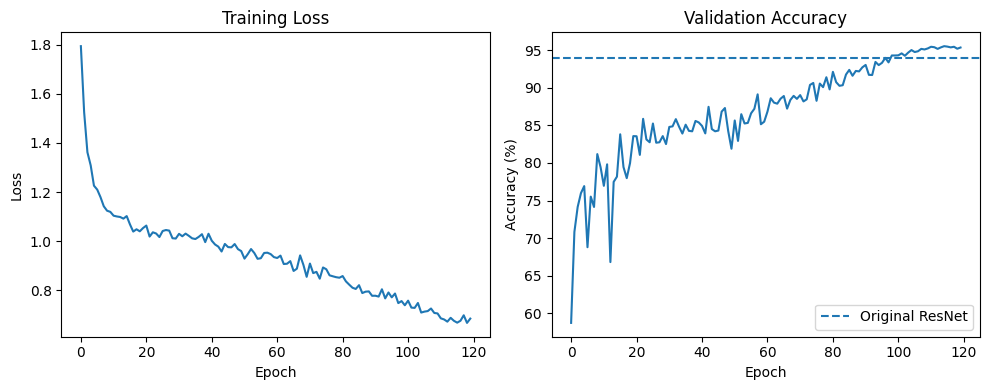

Best validation accuracy: 95.56%


In [8]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(val_accuracies)
plt.axhline(
    94.04,
    linestyle="--",
    label="Original ResNet"
)
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

print(f"Best validation accuracy: {best_accuracy:.2f}%")

In [9]:
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()
predictions = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            original = model(images)
            flipped = model(torch.flip(images, dims=[3]))

        probabilities = (
            torch.softmax(original.float(), dim=1)
            + torch.softmax(flipped.float(), dim=1)
        ) / 2

        predictions.extend(
            probabilities.argmax(1).cpu().tolist()
        )

prediction_df = test_df[["id"]].copy()
prediction_df["label"] = predictions

submission = pd.read_csv(
    project / "sample_submission.csv"
)[["id"]]

submission = submission.merge(
    prediction_df,
    on="id",
    how="left",
    validate="one_to_one"
)

assert len(submission) == 2000
assert submission["label"].notna().all()

submission["label"] = submission["label"].astype(int)

submission.to_csv(
    project / "submission03.csv",
    index=False
)

print("Saved submission03.csv")
print(submission.head())

Saved submission03.csv
   id  label
0   0      6
1   1      3
2   2      3
3   3      9
4   4      3


In [10]:
print(f"Best V2 validation accuracy: {best_accuracy:.2f}%")

Best V2 validation accuracy: 95.56%


In [11]:
model_v1 = CustomResNet().to(device)
model_v2 = CustomResNet().to(device)

model_v1.load_state_dict(
    torch.load(
        project / "best_resnet.pth",
        map_location=device,
        weights_only=True
    )
)

model_v2.load_state_dict(
    torch.load(
        project / "best_resnet_v2.pth",
        map_location=device,
        weights_only=True
    )
)

model_v1.eval()
model_v2.eval()

print("Both models loaded successfully!")

Both models loaded successfully!


In [12]:
predictions = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)
        flipped = torch.flip(images, dims=[3])

        # Original model with TTA
        p1 = (
            torch.softmax(model_v1(images), dim=1)
            + torch.softmax(model_v1(flipped), dim=1)
        ) / 2

        # V2 model with TTA
        p2 = (
            torch.softmax(model_v2(images), dim=1)
            + torch.softmax(model_v2(flipped), dim=1)
        ) / 2

        # Weighted ensemble: 30% V1, 70% V2
        combined = 0.3 * p1 + 0.7 * p2

        predictions.extend(
            combined.argmax(1).cpu().tolist()
        )

prediction_df = test_df[["id"]].copy()
prediction_df["label"] = predictions

submission = pd.read_csv(
    project / "sample_submission.csv"
)[["id"]]

submission = submission.merge(
    prediction_df,
    on="id",
    how="left",
    validate="one_to_one"
)

assert len(submission) == 2000
assert submission["label"].notna().all()

submission["label"] = submission["label"].astype(int)

submission.to_csv(
    project / "submission_ensemble.csv",
    index=False
)

print("Saved submission_ensemble.csv")
print(submission.head())

Saved submission_ensemble.csv
   id  label
0   0      6
1   1      3
2   2      3
3   3      9
4   4      3


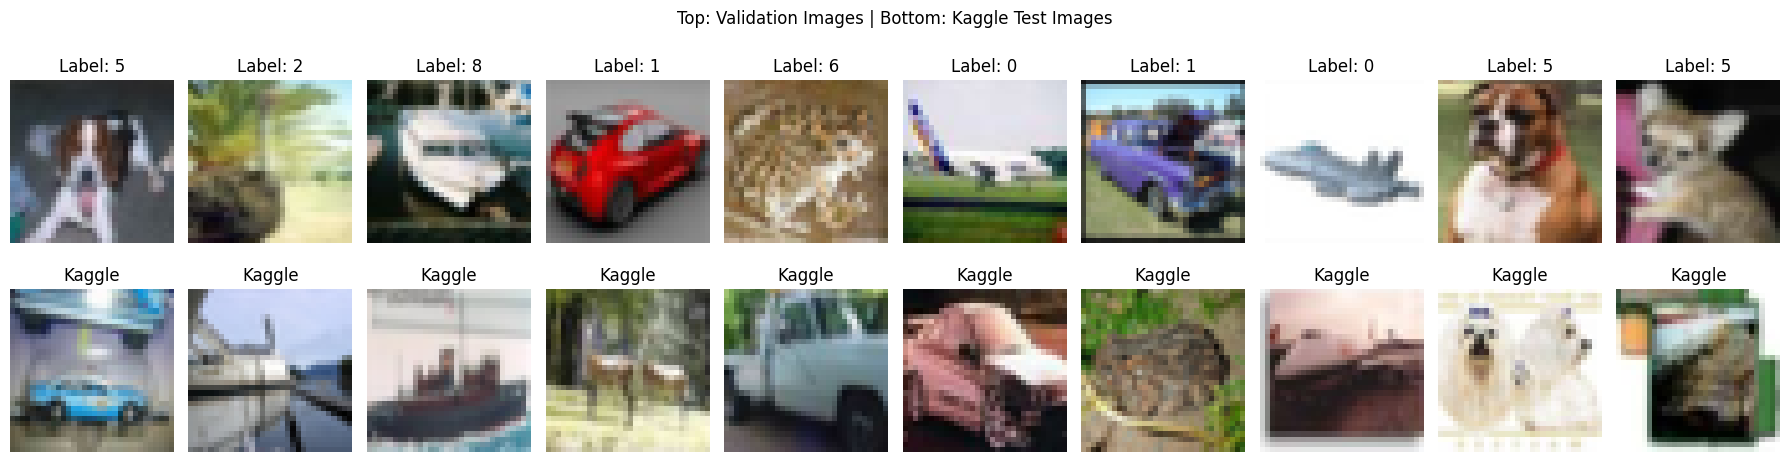

In [13]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

fig, axes = plt.subplots(2, 10, figsize=(18, 5))

# Random validation images
val_samples = val_split.sample(10, random_state=42)

for i, (_, row) in enumerate(val_samples.iterrows()):
    image = Image.open(train_paths[row["filename"]])
    axes[0, i].imshow(image)
    axes[0, i].set_title(f"Label: {row['label']}")
    axes[0, i].axis("off")

# Random Kaggle test images
test_samples = test_df.sample(10, random_state=42)

for i, (_, row) in enumerate(test_samples.iterrows()):
    image = Image.open(test_paths[row["filename"]])
    axes[1, i].imshow(image)
    axes[1, i].set_title("Kaggle")
    axes[1, i].axis("off")

plt.suptitle("Top: Validation Images | Bottom: Kaggle Test Images")
plt.tight_layout()
plt.show()

Validation average confidence: 0.85873437
Kaggle average confidence: 0.81892544


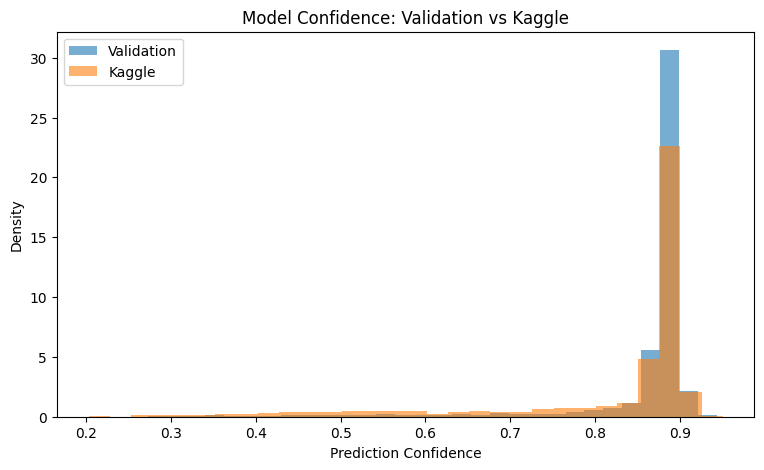

In [14]:
model_v2.eval()

val_confidences = []
test_confidences = []

with torch.no_grad():

    for images, labels in val_loader:
        images = images.to(device)

        outputs = model_v2(images)
        probabilities = torch.softmax(outputs, dim=1)

        confidence = probabilities.max(dim=1).values
        val_confidences.extend(confidence.cpu().numpy())

    for images in test_loader:
        images = images.to(device)

        outputs = model_v2(images)
        probabilities = torch.softmax(outputs, dim=1)

        confidence = probabilities.max(dim=1).values
        test_confidences.extend(confidence.cpu().numpy())

print("Validation average confidence:", np.mean(val_confidences))
print("Kaggle average confidence:", np.mean(test_confidences))

plt.figure(figsize=(9, 5))

plt.hist(
    val_confidences,
    bins=30,
    alpha=0.6,
    density=True,
    label="Validation"
)

plt.hist(
    test_confidences,
    bins=30,
    alpha=0.6,
    density=True,
    label="Kaggle"
)

plt.xlabel("Prediction Confidence")
plt.ylabel("Density")
plt.title("Model Confidence: Validation vs Kaggle")
plt.legend()
plt.show()

In [15]:
model_v2 = CustomResNet().to(device)

model_v2.load_state_dict(
    torch.load(
        project / "best_resnet_v2.pth",
        map_location=device,
        weights_only=True
    )
)

model_v2.eval()

def predict_with_tta(model, images):
    # Original image and horizontal flip
    versions = [
        images,
        torch.flip(images, dims=[3])
    ]

    # Shift the image by one pixel in four directions
    versions.extend([
        torch.roll(images, 1, dims=2),
        torch.roll(images, -1, dims=2),
        torch.roll(images, 1, dims=3),
        torch.roll(images, -1, dims=3)
    ])

    probabilities = 0

    for version in versions:
        outputs = model(version)
        probabilities += torch.softmax(outputs, dim=1)

    return probabilities / len(versions)


predictions = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)

        probabilities = predict_with_tta(model_v2, images)

        predictions.extend(
            probabilities.argmax(1).cpu().tolist()
        )

prediction_df = test_df[["id"]].copy()
prediction_df["label"] = predictions

submission = pd.read_csv(
    project / "sample_submission.csv"
)[["id"]]

submission = submission.merge(
    prediction_df,
    on="id",
    how="left",
    validate="one_to_one"
)

assert len(submission) == 2000
assert submission["label"].notna().all()

submission["label"] = submission["label"].astype(int)

submission.to_csv(
    project / "submission_multitta.csv",
    index=False
)

print("Saved submission_multitta.csv")

Saved submission_multitta.csv
